# 02. Retention Cohorts

Retention asks whether visitors return after their first week. It is more useful than total traffic when assessing whether Venture is becoming a habit.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

WORKSPACE = Path.cwd()
if WORKSPACE.name == "notebooks":
    WORKSPACE = WORKSPACE.parent

sys.path.insert(0, str(WORKSPACE / "src"))

from venture_ds import (
    load_exports,
    load_optional_export,
    safe_rate,
    wilson_interval,
    ordered_session_funnel,
    add_sample_warning,
)

exports = load_exports(WORKSPACE / "data" / "raw")
events = exports["events"]
sessions = exports["sessions"]
feedback = exports["feedback"]
inventory = exports["inventory"]

exports["_files"]

,dataset,path,found
0,events,C:\Users\ppmal\Documents\Projects\venture-prod...,True
1,sessions,C:\Users\ppmal\Documents\Projects\venture-prod...,True
2,feedback,C:\Users\ppmal\Documents\Projects\venture-prod...,True
3,inventory,C:\Users\ppmal\Documents\Projects\venture-prod...,True


In [2]:
if events.empty or events["visitor_id"].dropna().empty:
    print("Visitor-level events are required for retention.")
else:
    activity = (
        events.dropna(subset=["visitor_id", "created_at"])
        [["visitor_id", "created_at"]]
        .drop_duplicates()
        .copy()
    )
    activity["activity_week"] = (
        activity["created_at"]
        .dt.to_period("W")
        .apply(lambda value: value.start_time)
    )
    first_week = (
        activity.groupby("visitor_id")["activity_week"]
        .min()
        .rename("cohort_week")
    )
    activity = activity.join(first_week, on="visitor_id")
    activity["week_index"] = (
        (activity["activity_week"] - activity["cohort_week"])
        .apply(lambda delta: delta.days // 7)
    )

    cohort_counts = (
        activity.groupby(["cohort_week", "week_index"])["visitor_id"]
        .nunique()
        .unstack(fill_value=0)
    )
    cohort_sizes = cohort_counts[0]
    retention = cohort_counts.divide(cohort_sizes, axis=0)

    display((retention * 100).round(1))

C:\Users\ppmal\AppData\Local\Temp\ipykernel_56784\3610493544.py:12: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .dt.to_period("W")


week_index,0
cohort_week,
2026-07-20,100.0


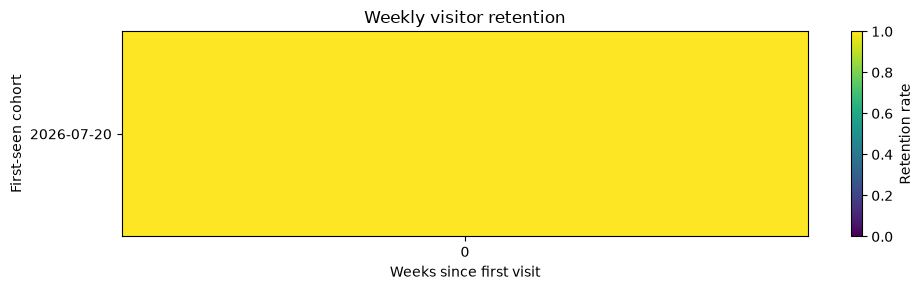

In [3]:
if "retention" in globals() and not retention.empty:
    fig, ax = plt.subplots(figsize=(10, max(3, len(retention) * 0.6)))
    image = ax.imshow(retention.values, aspect="auto", vmin=0, vmax=1)
    ax.set_title("Weekly visitor retention")
    ax.set_xlabel("Weeks since first visit")
    ax.set_ylabel("First-seen cohort")
    ax.set_xticks(range(len(retention.columns)))
    ax.set_xticklabels(retention.columns)
    ax.set_yticks(range(len(retention.index)))
    ax.set_yticklabels([str(value.date()) for value in retention.index])
    fig.colorbar(image, ax=ax, label="Retention rate")
    plt.tight_layout()

## Caution

Recent cohorts have not had enough time to reach later weeks. Blank or unobservable cells should not be treated as zero retention.